In [1]:
import tensorflow as tf
from google.colab import drive
import os

drive.mount('/content/drive')



Mounted at /content/drive


STEP 1: LOAD MODEL

In [2]:
BASE_PATH = '/content/drive/MyDrive/Paddy_Classification'
LABELED_DIR = os.path.join(BASE_PATH, 'Labeled_data')
INFERENCE_DIR = os.path.join(BASE_PATH, 'Unlabeled_inference')

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    LABELED_DIR, validation_split=0.2, subset="training",
    seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    LABELED_DIR, validation_split=0.2, subset="validation",
    seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE
)
class_names = train_ds.class_names

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

MODEL_PATH = os.path.join(BASE_PATH, 'best_paddy_model.keras')
model = tf.keras.models.load_model(MODEL_PATH)
print("✅ Model and datasets restored.")

Found 8660 files belonging to 2 classes.
Using 6928 files for training.
Found 8660 files belonging to 2 classes.
Using 1732 files for validation.
✅ Model and datasets restored.


STEP 2: Find the best decision threshold

In [4]:
import numpy as np
from sklearn.metrics import precision_recall_curve, f1_score, classification_report

# 1. Predict on the entire dataset at once (drastically faster)
y_pred_probs = model.predict(val_ds, verbose=1).flatten()

# 2. Extract true labels efficiently using list comprehension
y_true = np.concatenate([y.numpy() for _, y in val_ds], axis=0)

# Ensure shapes match
y_true = y_true.flatten()

# 3. Find optimal threshold
precisions, recalls, thresholds = precision_recall_curve(y_true, y_pred_probs)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)
best_idx = np.argmax(f1_scores[:-1])  # last point has no threshold
best_threshold = thresholds[best_idx]

print(f"Default threshold (0.5) F1: {f1_score(y_true, (y_pred_probs > 0.5).astype(int)):.4f}")
print(f"Best threshold: {best_threshold:.3f}  →  F1: {f1_scores[best_idx]:.4f}")
print(f"  Precision at best threshold: {precisions[best_idx]:.4f}")
print(f"  Recall at best threshold:    {recalls[best_idx]:.4f}")

print("\n--- Classification report at BEST threshold ---")
y_pred_best = (y_pred_probs > best_threshold).astype(int)
print(classification_report(y_true, y_pred_best, target_names=class_names))

55/55 ━━━━━━━━━━━━━━━━━━━━ 112s 2s/step
Default threshold (0.5) F1: 0.9036
Best threshold: 0.365  →  F1: 0.9172
  Precision at best threshold: 0.9373
  Recall at best threshold:    0.8980

--- Classification report at BEST threshold ---
              precision    recall  f1-score   support

     Healthy       0.91      0.94      0.93       899
   Unhealthy       0.94      0.90      0.92       833

    accuracy                           0.92      1732
   macro avg       0.92      0.92      0.92      1732
weighted avg       0.92      0.92      0.92      1732



STEP 3: Error analysis

In [5]:
import matplotlib.pyplot as plt
import numpy as np

print("Locating false negatives using existing predictions...")

# Reuse predictions from Cell 2 — no need to re-run the model
y_pred_best_labels = (y_pred_probs > best_threshold).astype(int)

# False negatives: actually Unhealthy (1), predicted Healthy (0)
fn_mask = (y_true == 1) & (y_pred_best_labels == 0)
fn_indices = set(np.where(fn_mask)[0][:8])  # only need the first 8 for display

print(f"False negatives at threshold {best_threshold:.3f}: {fn_mask.sum()} total")
print(f"Fetching images for {len(fn_indices)} of them to display...\n")

# Walk through val_ds ONCE, only grabbing images at the target indices
fn_images = {}
running_idx = 0
total_batches = len(val_ds)

for batch_num, (images, labels) in enumerate(val_ds):
    batch_size = images.shape[0]
    batch_indices = range(running_idx, running_idx + batch_size)

    for local_i, global_i in enumerate(batch_indices):
        if global_i in fn_indices:
            fn_images[global_i] = images[local_i].numpy()

    running_idx += batch_size
    print(f"\rScanning batch {batch_num + 1}/{total_batches}...", end="")

    if len(fn_images) == len(fn_indices):
        print("\n✅ Found all target images — stopping early.")
        break

print(f"\nCollected {len(fn_images)} images.\n")



Locating false negatives using existing predictions...
False negatives at threshold 0.365: 86 total
Fetching images for 8 of them to display...

Scanning batch 3/55...
✅ Found all target images — stopping early.

Collected 8 images.



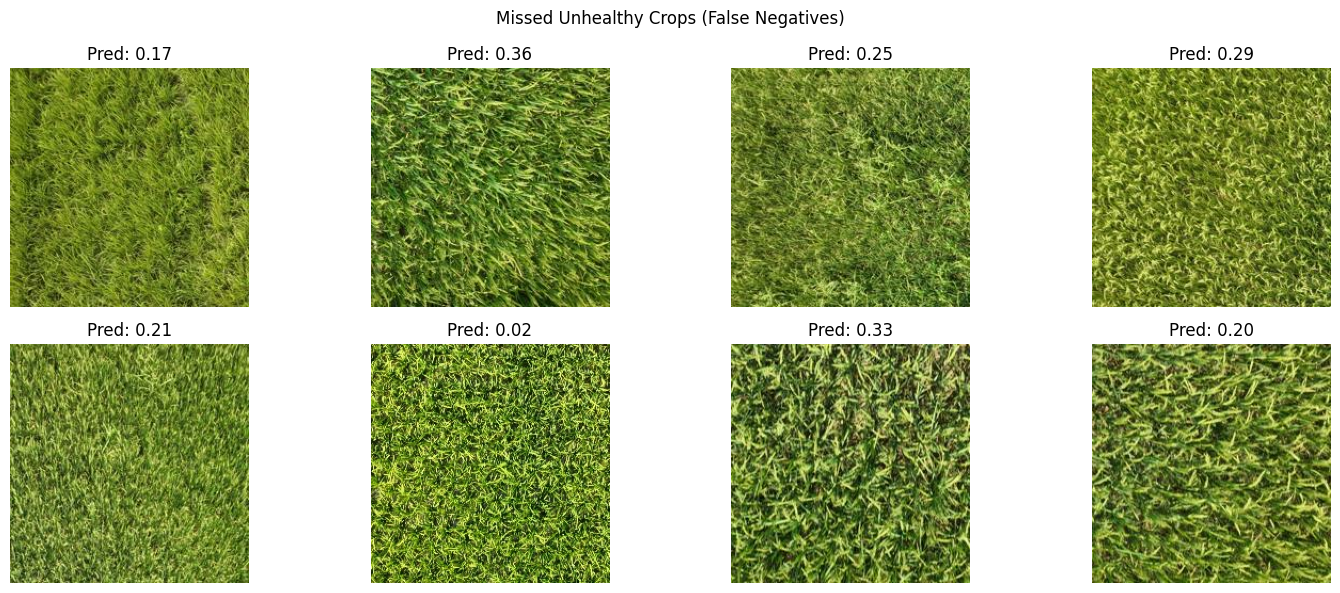

In [6]:
# ---------------------------------------------------------
# Plot
# ---------------------------------------------------------
plt.figure(figsize=(15, 6))
for i, idx in enumerate(fn_images.keys()):
    plt.subplot(2, 4, i + 1)
    plt.imshow(fn_images[idx].astype("uint8"))
    plt.title(f"Pred: {y_pred_probs[idx]:.2f}")
    plt.axis("off")
plt.suptitle("Missed Unhealthy Crops (False Negatives)")
plt.tight_layout()
plt.show()

STEP 4: Retrain: unfreeze layers + bigger head + class weights + better augmentation

In [7]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import (Dense, GlobalAveragePooling2D, Dropout, Input,
                                       RandomFlip, RandomRotation, RandomZoom,
                                       RandomBrightness, RandomContrast)
from tensorflow.keras.models import Model
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
import numpy as np

# Better augmentation: add photometric transforms
data_augmentation = tf.keras.Sequential([
    RandomFlip("horizontal_and_vertical"),
    RandomRotation(0.2),
    RandomZoom(0.2),
    RandomBrightness(0.2),
    RandomContrast(0.2),
], name="data_augmentation_v2")

In [8]:


# Fresh ResNet-50 base
base_model = ResNet50(input_shape=(224, 224, 3), include_top=False, weights='imagenet')

# Unfreeze more layers than before (last 60 instead of 30)
base_model.trainable = True
total_layers = len(base_model.layers)
fine_tune_at = total_layers - 60
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False
print(f"Unfrozen last {total_layers - fine_tune_at} of {total_layers} layers.")

# Bigger, regularized head
inputs = Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = tf.keras.applications.resnet.preprocess_input(x)
x = base_model(x, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu', kernel_regularizer=l2(1e-4))(x)
x = Dropout(0.5)(x)
outputs = Dense(1, activation='sigmoid')(x)

model_v2 = Model(inputs, outputs)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Unfrozen last 60 of 175 layers.


In [13]:
import shutil

# Clean up any stale cache/lockfiles from a previous interrupted run
LOCAL_CACHE_DIR = '/content/cache'
if os.path.exists(LOCAL_CACHE_DIR):
    shutil.rmtree(LOCAL_CACHE_DIR)
    print("🧹 Cleared stale cache directory.")
os.makedirs(LOCAL_CACHE_DIR, exist_ok=True)

# Rebuild datasets with local disk caching
train_ds = tf.keras.utils.image_dataset_from_directory(
    LABELED_DIR, validation_split=0.2, subset="training",
    seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE
).cache(os.path.join(LOCAL_CACHE_DIR, 'train_cache')).prefetch(tf.data.AUTOTUNE)

val_ds = tf.keras.utils.image_dataset_from_directory(
    LABELED_DIR, validation_split=0.2, subset="validation",
    seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE
).cache(os.path.join(LOCAL_CACHE_DIR, 'val_cache')).prefetch(tf.data.AUTOTUNE)

print("Warming up local cache (first pass will be slow, rest will be fast)...")
for _ in train_ds: pass
for _ in val_ds: pass
print("✅ Local disk cache built.")

# ---------------------------------------------------------
# STEP 1: Mixed precision — uses float16 on GPU compute, ~1.5-2x faster on T4/A100
# ---------------------------------------------------------
tf.keras.mixed_precision.set_global_policy('mixed_float16')
print("✅ Mixed precision enabled.")

# ---------------------------------------------------------
# STEP 2: Reduce unfrozen layers back to 30 (60 was the main slowdown)
# ---------------------------------------------------------
base_model.trainable = True
total_layers = len(base_model.layers)
fine_tune_at = total_layers - 30
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False
print(f"Unfrozen last {total_layers - fine_tune_at} of {total_layers} layers (reduced from 60).")

# Class weights
num_healthy = 4494
num_unhealthy = 4166
total = num_healthy + num_unhealthy
class_weight = {
    0: total / (2 * num_healthy),
    1: total / (2 * num_unhealthy) * 1.15
}
print("Class weights:", class_weight)

# Cosine decay LR schedule
STEPS_PER_EPOCH = 217
EPOCHS_V2 = 20
lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-4,
    decay_steps=STEPS_PER_EPOCH * EPOCHS_V2,
    alpha=0.01
)

model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()]
)



# ---------------------------------------------------------
# Custom Epoch Logger (unchanged)
# ---------------------------------------------------------
class EpochLogger(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.train_start = time.time()
        print(f"🕐 Training started at {datetime.now().strftime('%H:%M:%S')}\n")

    def on_epoch_begin(self, epoch, logs=None):
        self.epoch_start = time.time()

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        epoch_time = time.time() - self.epoch_start
        total_elapsed = time.time() - self.train_start
        lr = self.model.optimizer.learning_rate
        if isinstance(lr, tf.keras.optimizers.schedules.LearningRateSchedule):
            current_lr = float(lr(self.model.optimizer.iterations))
        else:
            current_lr = float(lr.numpy()) if hasattr(lr, 'numpy') else float(lr)
        print(
            f"\n📋 Epoch {epoch + 1}/{EPOCHS_V2} finished at {datetime.now().strftime('%H:%M:%S')} "
            f"| epoch time: {epoch_time:.0f}s | total elapsed: {total_elapsed/60:.1f} min\n"
            f"   loss: {logs.get('loss'):.4f}  acc: {logs.get('accuracy'):.4f}  "
            f"precision: {logs.get('precision'):.4f}  recall: {logs.get('recall'):.4f}\n"
            f"   val_loss: {logs.get('val_loss'):.4f}  val_acc: {logs.get('val_accuracy'):.4f}  "
            f"val_precision: {logs.get('val_precision'):.4f}  val_recall: {logs.get('val_recall'):.4f}\n"
            f"   current LR: {current_lr:.2e}\n" + "-" * 70
        )

    def on_train_end(self, logs=None):
        total_time = time.time() - self.train_start
        print(f"\n🏁 Training finished. Total time: {total_time/60:.1f} minutes.")

SAVE_PATH_V2 = os.path.join(BASE_PATH, 'best_paddy_model_v2.keras')
callbacks_v2 = [
    ModelCheckpoint(filepath=SAVE_PATH_V2, monitor='val_accuracy', mode='max',
                     save_best_only=True, verbose=1),
    EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True, verbose=1),
    EpochLogger()
]

print("🚀 Starting improved training run...")
history_v2 = model_v2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_V2,
    class_weight=class_weight,
    callbacks=callbacks_v2,
    verbose=1
)
print("✅ Training complete. Best model saved as best_paddy_model_v2.keras")

🧹 Cleared stale cache directory.
Found 8660 files belonging to 2 classes.
Using 6928 files for training.
Found 8660 files belonging to 2 classes.
Using 1732 files for validation.
Warming up local cache (first pass will be slow, rest will be fast)...
✅ Local disk cache built.
✅ Mixed precision enabled.
Unfrozen last 30 of 175 layers (reduced from 60).
Class weights: {0: 0.9635068980863374, 1: 1.1952712433989436}
🚀 Starting improved training run...
🕐 Training started at 10:03:21

Epoch 1/20
217/217 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step - accuracy: 0.8646 - loss: 0.3317 - precision: 0.8508 - recall: 0.8597
Epoch 1: val_accuracy improved from None to 0.91917, saving model to /content/drive/MyDrive/Paddy_Classification/best_paddy_model_v2.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Paddy_Classification/best_paddy_model_v2.keras

📋 Epoch 1/20 finished at 10:04:51 | epoch time: 90s | total elapsed: 1.5 min
   loss: 0.2431  acc: 0.9120  precision: 0.9029  recall: 0.9154
   val

In [14]:
SAVE_PATH_V2_FINAL = os.path.join(BASE_PATH, 'final_paddy_resnet50_v2.keras')
model_v2.save(SAVE_PATH_V2_FINAL)
print(f"✅ Model saved to: {SAVE_PATH_V2_FINAL}")

✅ Model saved to: /content/drive/MyDrive/Paddy_Classification/final_paddy_resnet50_v2.keras


In [15]:
model_v2 = tf.keras.models.load_model(SAVE_PATH_V2_FINAL)
print("✅ Model v2 loaded successfully.")

✅ Model v2 loaded successfully.


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'loss_scale_optimizer', because it has 85 variables whereas the saved optimizer has 81 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 81 variables whereas the saved optimizer has 0 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Best threshold: 0.391
              precision    recall  f1-score   support

     Healthy       0.97      0.96      0.96       899
   Unhealthy       0.96      0.97      0.96       833

    accuracy                           0.96      1732
   macro avg       0.96      0.96      0.96      1732
weighted avg       0.96      0.96      0.96      1732



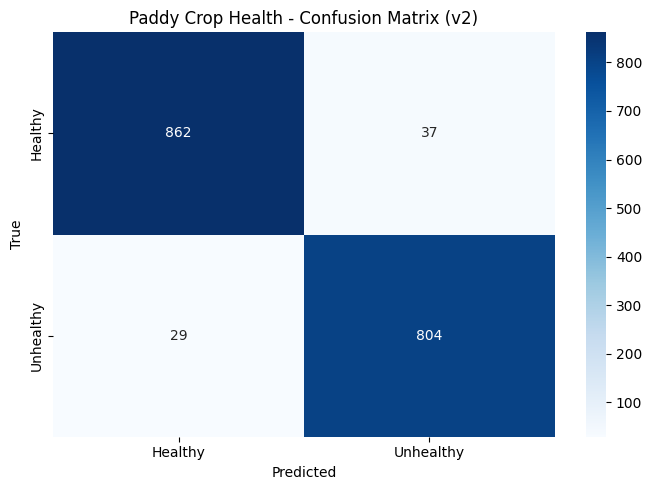

In [16]:
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_curve, f1_score

y_true_v2, y_pred_probs_v2 = [], []
for images, labels in val_ds:
    y_true_v2.extend(labels.numpy())
    y_pred_probs_v2.extend(model_v2.predict(images, verbose=0).flatten())

y_true_v2 = np.array(y_true_v2)
y_pred_probs_v2 = np.array(y_pred_probs_v2)

precisions, recalls, thresholds = precision_recall_curve(y_true_v2, y_pred_probs_v2)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)
best_idx = np.argmax(f1_scores[:-1])
best_threshold_v2 = thresholds[best_idx]

y_pred_v2 = (y_pred_probs_v2 > best_threshold_v2).astype(int)

print(f"Best threshold: {best_threshold_v2:.3f}")
print(classification_report(y_true_v2, y_pred_v2, target_names=class_names))

cm = confusion_matrix(y_true_v2, y_pred_v2)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Paddy Crop Health - Confusion Matrix (v2)')
plt.xlabel('Predicted'); plt.ylabel('True')
plt.tight_layout()
plt.show()

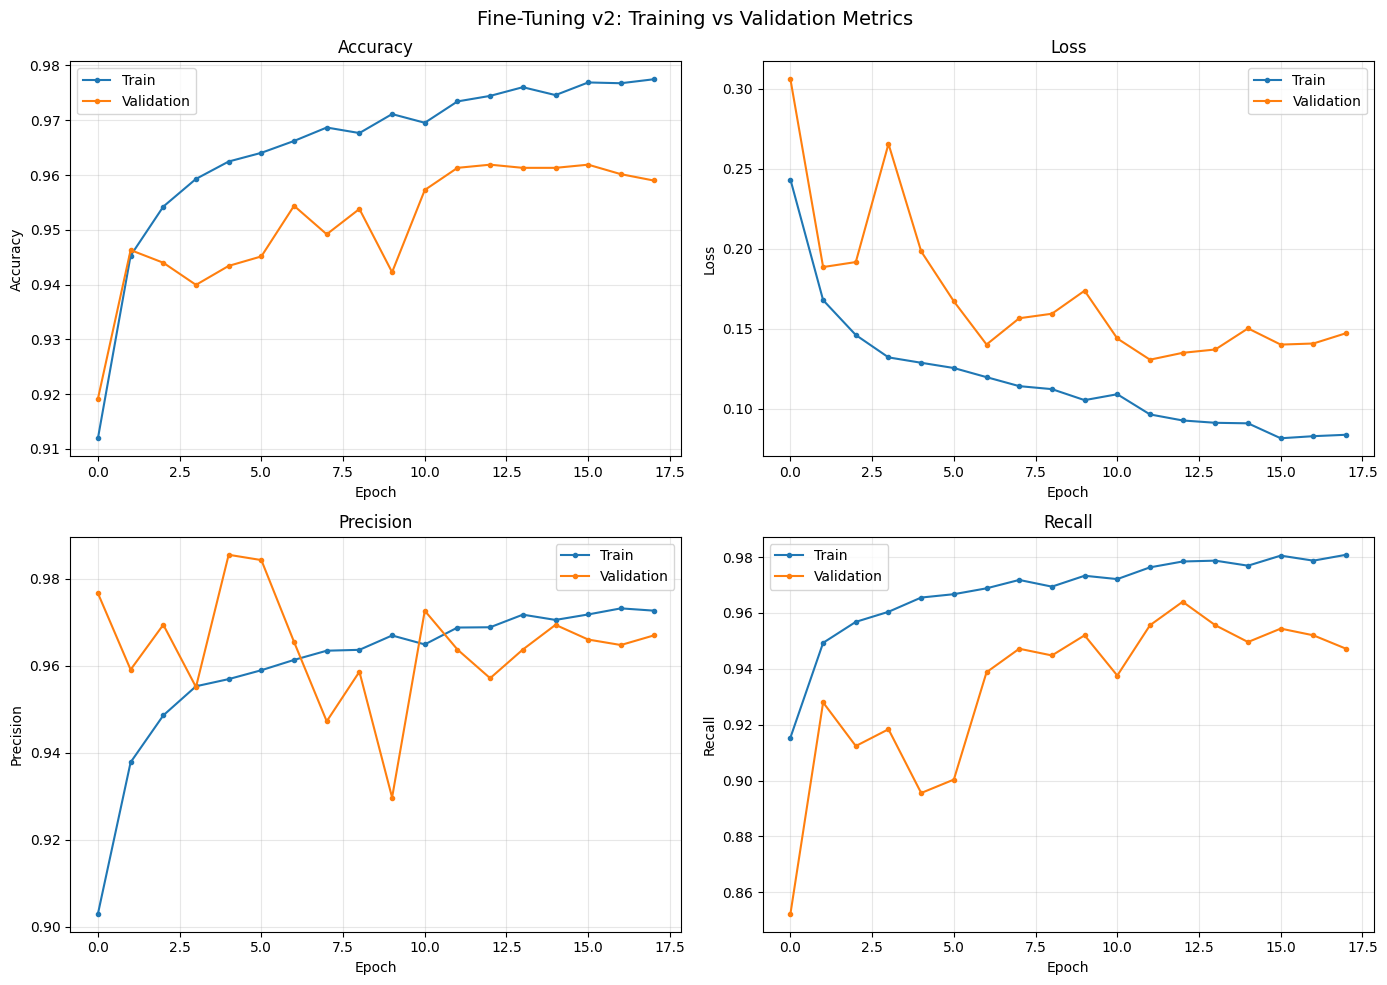

In [17]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

metrics = [
    ('accuracy', 'val_accuracy', 'Accuracy'),
    ('loss', 'val_loss', 'Loss'),
    ('precision', 'val_precision', 'Precision'),
    ('recall', 'val_recall', 'Recall')
]

for ax, (train_key, val_key, title) in zip(axes.flat, metrics):
    ax.plot(history_v2.history[train_key], label='Train', marker='o', markersize=3)
    ax.plot(history_v2.history[val_key], label='Validation', marker='o', markersize=3)
    ax.set_title(title)
    ax.set_xlabel('Epoch')
    ax.set_ylabel(title)
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle('Fine-Tuning v2: Training vs Validation Metrics', fontsize=14)
plt.tight_layout()
plt.show()

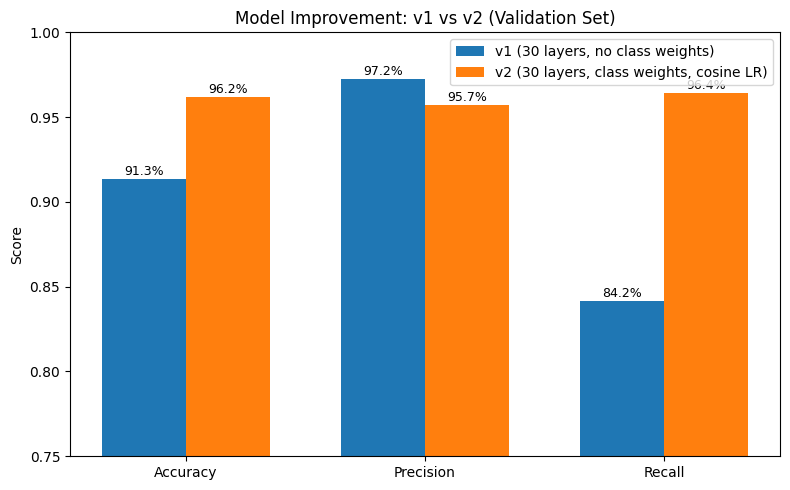

In [19]:
labels = ['Accuracy', 'Precision', 'Recall']
v1_scores = [0.9134, 0.9723, 0.8415]
v2_scores = [0.9619, 0.9571, 0.9640]  # epoch 13 checkpoint numbers

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
bars1 = ax.bar(x - width/2, v1_scores, width, label='v1 (30 layers, no class weights)')
bars2 = ax.bar(x + width/2, v2_scores, width, label='v2 (30 layers, class weights, cosine LR)')

ax.set_ylabel('Score')
ax.set_title('Model Improvement: v1 vs v2 (Validation Set)')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0.75, 1.0)
ax.legend()

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.1%}', xy=(bar.get_x() + bar.get_width()/2, height),
                     xytext=(0, 3), textcoords="offset points", ha='center', fontsize=9)

plt.tight_layout()
plt.show()